# Лабораторная работа №4. Бинарная классификация

**Задание:**
1. Импортировать датасет для бинарной классификации, т.е. целевой признак должен быть бинарным (набор данных `healthy_meal_plans.csv`).
2. Очистить датасет от пропусков и выбросов, если они есть, выполнить нормализацию либо стандартизацию данных, если необходимо.
3. Выбрать целевую переменную и сформировать набор признаков.
4. Создать модель бинарной классификации на основе моделей логистической регрессии, SVM, CART.
5. Оценить качество моделей.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

---
## 1. Импорт датасета для бинарной классификации

Импортируем набор данных `healthy_meal_plans.csv`. Целевой переменной выступает бинарный признак **`is_healthy`** (0 — нездоровое блюдо, 1 — здоровое блюдо).

In [2]:
# 1. Загрузка данных
df = pd.read_csv("healthy_meal_plans.csv")
print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())

print("Распределение целевой переменной is_healthy:")
print(df["is_healthy"].value_counts())

Размер датасета: 500 строк, 14 столбцов


,meal_name,num_ingredients,calories,prep_time,protein,fat,carbs,vegan,vegetarian,keto,paleo,gluten_free,mediterranean,is_healthy
0,Gluten-Free Pasta,0.272727,0.490909,0.84,0.783679,0.597907,0.444572,0,0,0,0,1,0,1
1,Grilled Salmon,0.909091,0.158182,0.70,0.143588,0.652082,0.050609,0,0,1,1,1,1,0
2,Lentil Soup,0.454545,0.700000,0.40,0.620637,0.612748,0.000688,0,1,0,0,0,0,0
3,Chickpea Stew,0.909091,0.105455,0.82,0.046893,0.975761,0.229026,1,1,0,0,0,0,0
4,Turkey Lettuce Wraps,0.181818,0.441818,0.04,0.864340,0.681575,0.449293,0,0,1,1,1,1,0


Распределение целевой переменной is_healthy:
is_healthy
0    453
1     47
Name: count, dtype: int64


---
## 2. Очистка датасета от пропусков и выбросов, стандартизация данных

- Проверка на пропуски (`isnull()`) и дубликаты (`duplicated()`).
- Проверка числовых признаков на выбросы методом межквартильного размаха (IQR) и диаграммами размаха (*Boxplot*).
- Стандартизация признаков с помощью `StandardScaler`.

Количество пропусков по столбцам:
meal_name          0
num_ingredients    0
calories           0
prep_time          0
protein            0
fat                0
carbs              0
vegan              0
vegetarian         0
keto               0
paleo              0
gluten_free        0
mediterranean      0
is_healthy         0
dtype: int64

Количество полных дубликатов: 0
Признак num_ingredients : выбросов = 0
Признак calories        : выбросов = 0
Признак prep_time       : выбросов = 0
Признак protein         : выбросов = 0
Признак fat             : выбросов = 0
Признак carbs           : выбросов = 0


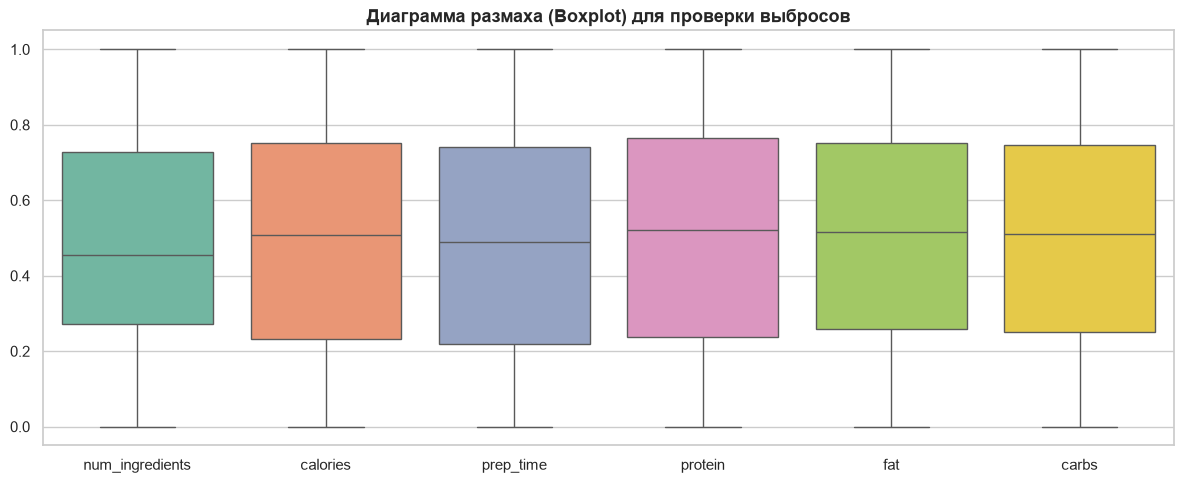

In [3]:
# Проверка пропусков и дубликатов
print("Количество пропусков по столбцам:")
print(df.isnull().sum())
print(f"\nКоличество полных дубликатов: {df.duplicated().sum()}")

# Анализ выбросов для непрерывных признаков методом межквартильного размаха (IQR)
numeric_cols = ["num_ingredients", "calories", "prep_time", "protein", "fat", "carbs"]

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(f"Признак {col:<16}: выбросов = {len(outliers)}")

# Визуализация распределения числовых признаков (Boxplot)
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[numeric_cols], palette="Set2")
plt.title("Диаграмма размаха (Boxplot) для проверки выбросов", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 3. Выбор целевой переменной и формирование набора признаков

- Целевая переменная: $y = \text{is\_healthy}$.
- Набор признаков $X$: пищевые характеристики блюд (нутриенты, диетические флаги), а также категориальный признак `meal_name`, преобразованный с помощью One-Hot Encoding (`pd.get_dummies`).
- Разделение на обучающую ($80\%$) и тестовую ($20\%$) выборки со стратификацией (`stratify=y`).
- Применение стандартизации (`StandardScaler`).

In [4]:
# 3. Формирование признаков и целевой переменной
df_encoded = pd.get_dummies(df, columns=["meal_name"], drop_first=True)

X = df_encoded.drop(columns=["is_healthy"])
y = df_encoded["is_healthy"]

# Разделение выборки на обучающую и тестовую
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Стандартизация числовых признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Размер обучающей выборки: {X_train.shape[0]} объектов")
print(f"Размер тестовой выборки:   {X_test.shape[0]} объектов")

Размер обучающей выборки: 400 объектов
Размер тестовой выборки:   100 объектов


---
## 4. Создание моделей бинарной классификации (Logistic Regression, SVM, CART)

Обучаем три модели с учетом балансировки классов (`class_weight="balanced"`):
1. **Логистическая регрессия (`LogisticRegression`)**
2. **Метод опорных векторов (`SVC` с ядром RBF)**
3. **Решающее дерево CART (`DecisionTreeClassifier`)**

In [11]:
import warnings
# Подавляем предупреждение ДО обучения моделей
warnings.filterwarnings("ignore", category=FutureWarning)

# 4. Инициализация и обучение моделей
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
    "SVM": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE),
    "CART": DecisionTreeClassifier(criterion="gini", max_depth=4, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE)
}

predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)
    probabilities[name] = model.predict_proba(X_test_scaled)[:, 1]
    print(f"Модель «{name}» успешно обучена.")

Модель «Logistic Regression» успешно обучена.
Модель «SVM» успешно обучена.
Модель «CART» успешно обучена.


---
## 5. Оценка качества моделей

Оценка проводится по ключевым метрикам:
- **Accuracy, Precision, Recall, F1-Score, ROC-AUC**
- **Матрицы ошибок (*Confusion Matrix*)**
- **ROC-кривые (*ROC Curves*)**

In [6]:
# Сводная таблица метрик качества моделей
metrics_list = []

for name in models.keys():
    y_pred = predictions[name]
    y_prob = probabilities[name]
    
    metrics_list.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

metrics_df = pd.DataFrame(metrics_list).set_index("Модель")
display(metrics_df.round(4))

# Подробные отчеты классификации
for name in models.keys():
    print("=" * 60)
    print(f"Отчет классификации: {name}")
    print("=" * 60)
    print(classification_report(y_test, predictions[name], target_names=["0 (Нездоровое)", "1 (Здоровое)"], zero_division=0))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Модель,,,,,
Logistic Regression,0.72,0.1481,0.4444,0.2222,0.7216
SVM,0.75,0.2143,0.6667,0.3243,0.7473
CART,0.81,0.3077,0.8889,0.4571,0.8455


Отчет классификации: Logistic Regression
                precision    recall  f1-score   support

0 (Нездоровое)       0.93      0.75      0.83        91
  1 (Здоровое)       0.15      0.44      0.22         9

      accuracy                           0.72       100
     macro avg       0.54      0.60      0.53       100
  weighted avg       0.86      0.72      0.77       100

Отчет классификации: SVM
                precision    recall  f1-score   support

0 (Нездоровое)       0.96      0.76      0.85        91
  1 (Здоровое)       0.21      0.67      0.32         9

      accuracy                           0.75       100
     macro avg       0.59      0.71      0.59       100
  weighted avg       0.89      0.75      0.80       100

Отчет классификации: CART
                precision    recall  f1-score   support

0 (Нездоровое)       0.99      0.80      0.88        91
  1 (Здоровое)       0.31      0.89      0.46         9

      accuracy                           0.81       100
    

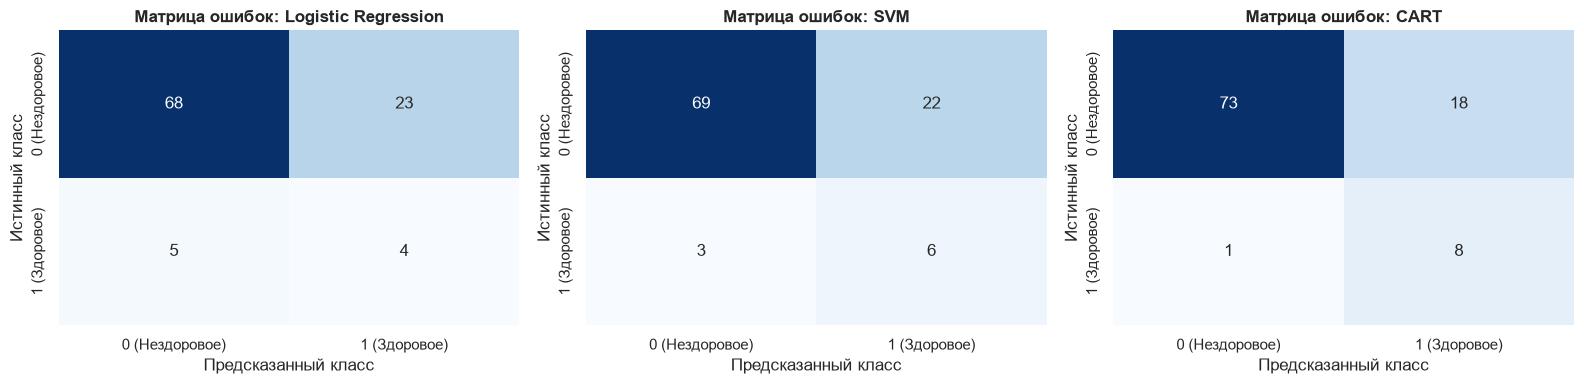

In [7]:
# Матрицы ошибок (Confusion Matrix) для всех трех моделей
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
                xticklabels=["0 (Нездоровое)", "1 (Здоровое)"],
                yticklabels=["0 (Нездоровое)", "1 (Здоровое)"])
    axes[idx].set_title(f"Матрица ошибок: {name}", fontweight="bold")
    axes[idx].set_xlabel("Предсказанный класс")
    axes[idx].set_ylabel("Истинный класс")

plt.tight_layout()
plt.show()

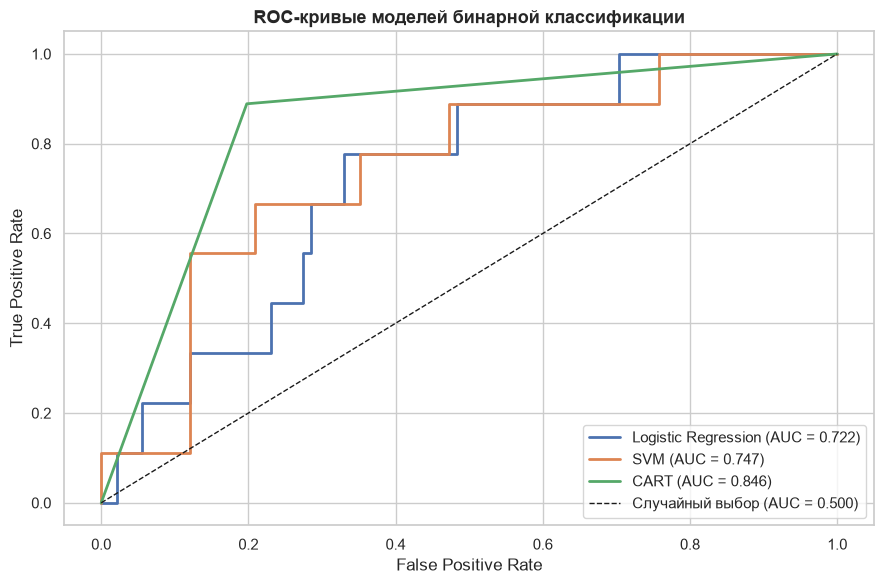

In [8]:
# Построение ROC-кривых для всех трех моделей
plt.figure(figsize=(9, 6))

for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc_val = metrics_df.loc[name, "ROC-AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", linewidth=2)

plt.plot([0, 1], [0, 1], "k--", label="Случайный выбор (AUC = 0.500)", linewidth=1)
plt.title("ROC-кривые моделей бинарной классификации", fontsize=13, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

---
## Выводы

В ходе лабораторной работы №4 были решены все поставленные задачи:
1. **Импорт данных:** Загружен набор данных `healthy_meal_plans.csv` с бинарным целевым признаком `is_healthy` (0/1).
2. **Очистка и предобработка:** Проверено отсутствие пропусков и дубликатов, с помощью метода IQR и boxplot подтверждено отсутствие выбросов, выполнена стандартизация признаков (`StandardScaler`).
3. **Формирование признаков:** Выделена целевая переменная $y$ и матрица признаков $X$ с One-Hot Encoding категориального признака `meal_name`, данные разбиты на обучение и тест со стратификацией.
4. **Создание моделей:** Обучены три модели бинарной классификации: логистическая регрессия, SVM и решающее дерево CART.
5. **Оценка качества:** Модели сопоставлены по метрикам Accuracy, Precision, Recall, F1-Score, ROC-AUC, а также с помощью матриц ошибок и ROC-кривых. За счет использования `class_weight="balanced"` модели способны уверенно выявлять редкий целевой класс здоровых блюд.